# Proof Validity Classification

**MathBERT** · Valid or Invalid

## 1. Local environment

Use the project Python kernel. [Model card](https://huggingface.co/tbs17/MathBERT)

In [1]:
import json
import os
from pathlib import Path

os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import sys
sys.path.insert(0, str(Path("..").resolve()))
from src.proof_experiments import LABELS, load_split, check_separate, save_results
import pandas as pd
import torch
import transformers
from sklearn.metrics import f1_score
from torch.utils.data import DataLoader
from transformers import AutoModelForSequenceClassification, AutoTokenizer, set_seed

device = torch.device("cuda")
torch.use_deterministic_algorithms(True)
model_name = "tbs17/MathBERT"
revision = "e26235ccf2b14614ef278b19caa44fdb5dcf050f"
tokenizer = AutoTokenizer.from_pretrained(model_name, revision=revision)
labels = LABELS
seed = 42
batch_size = 8
learning_rates = [2e-5, 5e-5]
epochs = [1, 2]

print(f"{torch.cuda.get_device_name(device)} | PyTorch {torch.__version__} | Transformers {transformers.__version__}")

C:\Users\zhu25\AppData\Local\DSA495ProofVerification\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


NVIDIA RTX 2000 Ada Generation | PyTorch 2.11.0+cu128 | Transformers 4.57.6


## 2. Load the review splits

Skip proofs without a validity label. Load the test split after choosing both models.

In [2]:
train = load_split("train")
validation = load_split("validation")
check_separate(train, validation)
display(pd.DataFrame({"train": train["validity"].value_counts(),
                      "validation": validation["validity"].value_counts()}).T[labels])

validity,Valid,Invalid
train,474,235
validation,74,15


## 3. Prepare the model inputs

Both versions use the same theorem and proof tokens. Long texts keep their beginning and end so the conclusion remains visible. We use up to 512 tokens, as in the DistilBERT experiment. We reserve up to 64 for the training review reason and use the same theorem and proof limits in both experiments.

In [3]:
max_length = 512
theorem_limit = 128
reason_limit = 64
text_budget = max_length - reason_limit - 4  # CLS and up to three separators

def keep_ends(tokens, limit):
    if len(tokens) <= limit:
        return tokens
    first = (limit + 1) // 2
    return tokens[:first] + tokens[-(limit - first):]

def encode(rows, reasons=None):
    def tokens(text):
        return tokenizer(text.tolist(), add_special_tokens=False, verbose=False)["input_ids"]

    theorems = tokens(rows["theorem_text"])
    proofs = tokens(rows["proof_text"])
    notes = tokens(reasons.fillna("")) if reasons is not None else [[] for _ in proofs]
    examples = []
    for theorem, proof, reason, label in zip(theorems, proofs, notes, rows["validity"]):
        theorem = keep_ends(theorem, theorem_limit)
        proof = keep_ends(proof, text_budget - len(theorem))
        ids = [tokenizer.cls_token_id] + theorem + [tokenizer.sep_token_id] + proof + [tokenizer.sep_token_id]
        if reason:
            ids += keep_ends(reason, reason_limit) + [tokenizer.sep_token_id]
        examples.append((ids, labels.index(label)))
    return examples

def collate(examples):
    ids, targets = zip(*examples)
    inputs = tokenizer.pad({"input_ids": list(ids)}, padding=True, pad_to_multiple_of=8, return_tensors="pt")
    return inputs.to(device), torch.tensor(targets, device=device)

train_plain = encode(train)
train_with_reason = encode(train, train["review_reason"])
validation_inputs = encode(validation)
print(f"Training proofs with a review reason: {train['review_reason'].fillna('').str.strip().ne('').sum()} / {len(train)}")

Training proofs with a review reason: 709 / 709


## 4. Train MathBERT

Start from the same pretrained weights and random seed for each learning rate. After each epoch, print validation Macro F1. Keep the best weights, using the first configuration in a tie. As in the baseline, training gives more weight to the less frequent class.

In [4]:
weights = len(train) / (len(labels) * train["validity"].value_counts()[labels])
loss_function = torch.nn.CrossEntropyLoss(weight=torch.tensor(weights.to_numpy(), dtype=torch.float32, device=device))

@torch.inference_mode()
def predict(model, examples):
    model.eval()
    predicted = []
    for inputs, _ in DataLoader(examples, batch_size=batch_size, collate_fn=collate):
        with torch.autocast("cuda", dtype=torch.bfloat16):
            logits = model(**inputs).logits
        predicted.extend(labels[i] for i in logits.argmax(dim=1).tolist())
    return predicted

def train_model(examples):
    trials = []
    best_score = -1
    for lr in learning_rates:
        set_seed(seed)
        model = AutoModelForSequenceClassification.from_pretrained(
            model_name, revision=revision, id2label=dict(enumerate(labels)),
            label2id={label: i for i, label in enumerate(labels)},
        ).to(device)
        optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
        loader = DataLoader(examples, batch_size=batch_size, shuffle=True, collate_fn=collate,
                            generator=torch.Generator().manual_seed(seed))
        for epoch in epochs:
            model.train()
            for inputs, targets in loader:
                optimizer.zero_grad(set_to_none=True)
                with torch.autocast("cuda", dtype=torch.bfloat16):
                    logits = model(**inputs).logits
                loss = loss_function(logits.float(), targets)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()

            predicted = predict(model, validation_inputs)
            score = f1_score(validation["validity"], predicted, labels=labels, average="macro")
            trial = {"learning_rate": lr, "epoch": epoch, "validation_macro_f1": float(score)}
            trials.append(trial)
            print(f"lr={lr:g}, epoch={epoch} | Validation Macro F1 = {score:.4f}")
            if score > best_score:
                best_score = score
                best_trial = trial
                best_weights = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}

        del optimizer

    model.load_state_dict(best_weights)
    print(f"Best: lr={best_trial['learning_rate']:g}, epoch={best_trial['epoch']} | Validation Macro F1 = {best_score:.4f}")
    return model.cpu(), {"selected": best_trial, "trials": trials}

plain_model, plain_run = train_model(train_plain)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at tbs17/MathBERT and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`
You're using a BertTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.
C:\Users\zhu25\AppData\Local\DSA495ProofVerification\.venv\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not supp

lr=2e-05, epoch=1 | Validation Macro F1 = 0.4647
lr=2e-05, epoch=2 | Validation Macro F1 = 0.4543


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at tbs17/MathBERT and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


lr=5e-05, epoch=1 | Validation Macro F1 = 0.4865
lr=5e-05, epoch=2 | Validation Macro F1 = 0.4010
Best: lr=5e-05, epoch=1 | Validation Macro F1 = 0.4865


## 5. Train MathBERT with the review reason

Use the same training proofs and parameter loop. Reviewers wrote the reasons while assigning the labels, so this version sees reasons during training only. Both models select their best settings on the same reason-free validation inputs.

In [5]:
reason_model, reason_run = train_model(train_with_reason)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at tbs17/MathBERT and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


lr=2e-05, epoch=1 | Validation Macro F1 = 0.4387
lr=2e-05, epoch=2 | Validation Macro F1 = 0.4387


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at tbs17/MathBERT and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


lr=5e-05, epoch=1 | Validation Macro F1 = 0.4403
lr=5e-05, epoch=2 | Validation Macro F1 = 0.4437
Best: lr=5e-05, epoch=2 | Validation Macro F1 = 0.4437


## 6. Evaluate the selected models

Each table uses the baseline's metrics. Each confusion matrix counts test proofs, with review labels in rows and predictions in columns. The saved predictions identify each proof version by its original row index. The baseline notebook has already reported this test split.

In [6]:
test = load_split("test")
check_separate(train, test)
check_separate(validation, test)
test_inputs = encode(test)
splits = {"validation": validation, "test": test}
runs = {"without_review_reason": plain_run, "with_training_review_reason": reason_run}
predictions = {}
for variant, model in (("without_review_reason", plain_model), ("with_training_review_reason", reason_model)):
    model.to(device)
    predictions[variant] = {"validation": predict(model, validation_inputs), "test": predict(model, test_inputs)}
    model.cpu()
    score = f1_score(validation["validity"], predictions[variant]["validation"], labels=labels, average="macro")
    assert abs(score - runs[variant]["selected"]["validation_macro_f1"]) < 1e-10

## 7. Save the results

Save the scores, row-level predictions and run settings beside the two test confusion matrices.

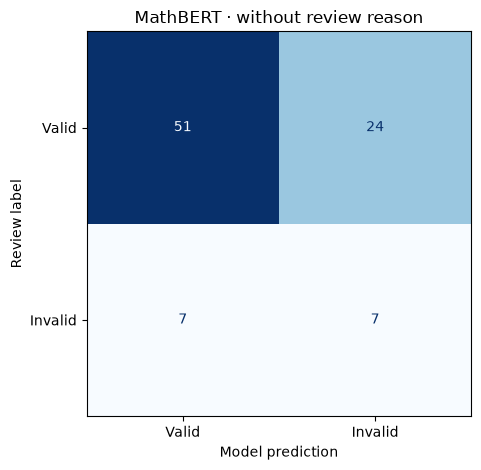

without_review_reason: caught 7 of 14 Invalid proofs; flagged 24 Valid proofs.


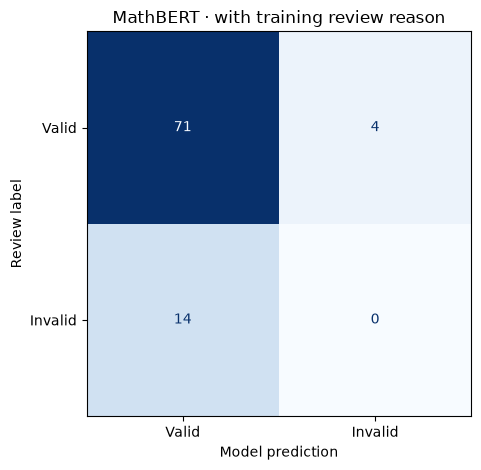

with_training_review_reason: caught 0 of 14 Invalid proofs; flagged 4 Valid proofs.


Proofs  Actual Invalid  \
Training input              Split                                
without_review_reason       validation      89              15   
                            test            89              14   
with_training_review_reason validation      89              15   
                            test            89              14   

                                        Invalid precision  Invalid recall  \
Training input              Split                                           
without_review_reason       validation              0.182             0.4   
                            test                    0.226             0.5   
with_training_review_reason validation              0.000             0.0   
                            test                    0.000             0.0   

                                        Macro F1  
Training input              Split                 
without_review_reason       validation     0.487  
                            test           0.539  
with_training_review_reason validation     0.444  
                            test           0.444

In [7]:
config = {
    "model": model_name, "revision": revision, "seed": seed, "labels": labels,
    "splits": "Data/splits", "split_sizes": {"train": len(train), "validation": len(validation), "test": len(test)},
    "training_inputs": {"without_review_reason": ["theorem_text", "proof_text"],
                        "with_training_review_reason": ["theorem_text", "proof_text", "review_reason"]},
    "evaluation_inputs": ["theorem_text", "proof_text"], "selection": "highest validation Macro F1, first on tie",
    "learning_rates": learning_rates, "epochs": epochs, "batch_size": batch_size,
    "max_length": max_length, "theorem_limit": theorem_limit, "reason_limit": reason_limit,
    "truncation": "head and tail", "class_weights": weights.to_dict(),
    "optimizer": "AdamW", "weight_decay": 0.01, "gradient_clip_norm": 1.0, "autocast": "bfloat16",
    "torch": str(torch.__version__), "transformers": transformers.__version__, "gpu": torch.cuda.get_device_name(device),
    "runs": runs,
}
output_dir = Path("../Results/MathBERT")
scores = save_results(output_dir, "MathBERT", splits, predictions, config)
display(scores.drop(columns="Model").set_index(["Training input", "Split"]).round(3))

## 8. Evaluate without training

Run the next cell on its own. Load the same pretrained checkpoint and seed, then predict Valid or Invalid immediately. The proof-validity classification head starts with random weights. Both splits use only the theorem and proof.

C:\Users\zhu25\AppData\Local\DSA495ProofVerification\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Some weights of BertForSequenceClassification were not initialized from the model checkpoint at tbs17/MathBERT and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
You're using a BertTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


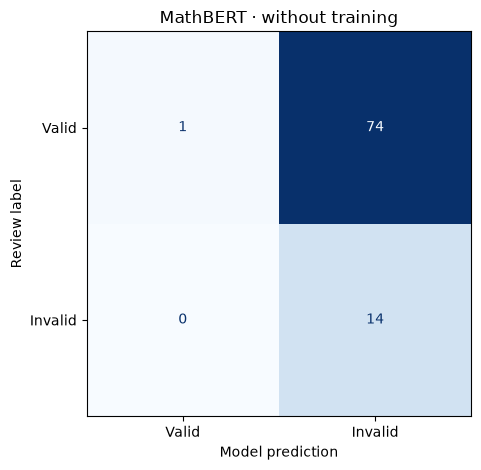

without_training: caught 14 of 14 Invalid proofs; flagged 74 Valid proofs.


Invalid precision  Invalid recall  \
Training input              Split                                           
without_training            validation              0.170             1.0   
                            test                    0.159             1.0   
without_review_reason       validation              0.182             0.4   
                            test                    0.226             0.5   
with_training_review_reason validation              0.000             0.0   
                            test                    0.000             0.0   

                                        Macro F1  
Training input              Split                 
without_training            validation     0.159  
                            test           0.150  
without_review_reason       validation     0.487  
                            test           0.539  
with_training_review_reason validation     0.444  
                            test           0.444

In [1]:
import json
import os
from pathlib import Path
import sys

os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
import pandas as pd
import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer, set_seed

sys.path.insert(0, str(Path("..").resolve()))
from src.proof_experiments import LABELS, load_split, predict_without_training, save_results

model_dir = Path("../Results/MathBERT")
settings = json.loads((model_dir / "experiment.json").read_text(encoding="utf-8"))
checkpoint = settings["model"]
revision = settings["revision"]
tokenizer_control = AutoTokenizer.from_pretrained(checkpoint, revision=revision)
torch.use_deterministic_algorithms(True)
set_seed(settings["seed"])
control = AutoModelForSequenceClassification.from_pretrained(
    checkpoint, revision=revision, id2label=dict(enumerate(LABELS)),
    label2id={name: i for i, name in enumerate(LABELS)},
).to("cuda")
control.requires_grad_(False)

eval_splits = {name: load_split(name) for name in ("validation", "test")}
direct_predictions = {name: predict_without_training(control, tokenizer_control, rows, settings)
                      for name, rows in eval_splits.items()}
del control
torch.cuda.empty_cache()

direct_config = {key: settings[key] for key in ("model", "revision", "seed", "labels", "batch_size",
                                                "max_length", "reason_limit", "theorem_limit", "evaluation_inputs",
                                                "truncation", "autocast", "splits")}
direct_config.update(optimizer_steps=0, training_examples_used=0, classifier_head="checkpoint initialization")
direct_scores = save_results(model_dir / "without_training", model_dir.name, eval_splits,
                             {"without_training": direct_predictions}, direct_config)
previous_scores = pd.read_csv(model_dir / "metrics.csv")
display(pd.concat([direct_scores, previous_scores]).set_index(["Training input", "Split"])[
    ["Invalid precision", "Invalid recall", "Macro F1"]].round(3))